Training plots:

In [19]:
from matplotlib import pyplot as plt
import json

In [20]:
log_gpt2 = json.load(open("checkpoints/gpt2_history.json"))
log_sp = json.load(open("checkpoints/sentencepiece_history.json"))
log_ws = json.load(open("checkpoints/whitespace_history.json"))

In [21]:
xs_train = [x['step'] for x in log_gpt2["train"]]
xs_val =[x['step'] for x in log_gpt2["validation"]]

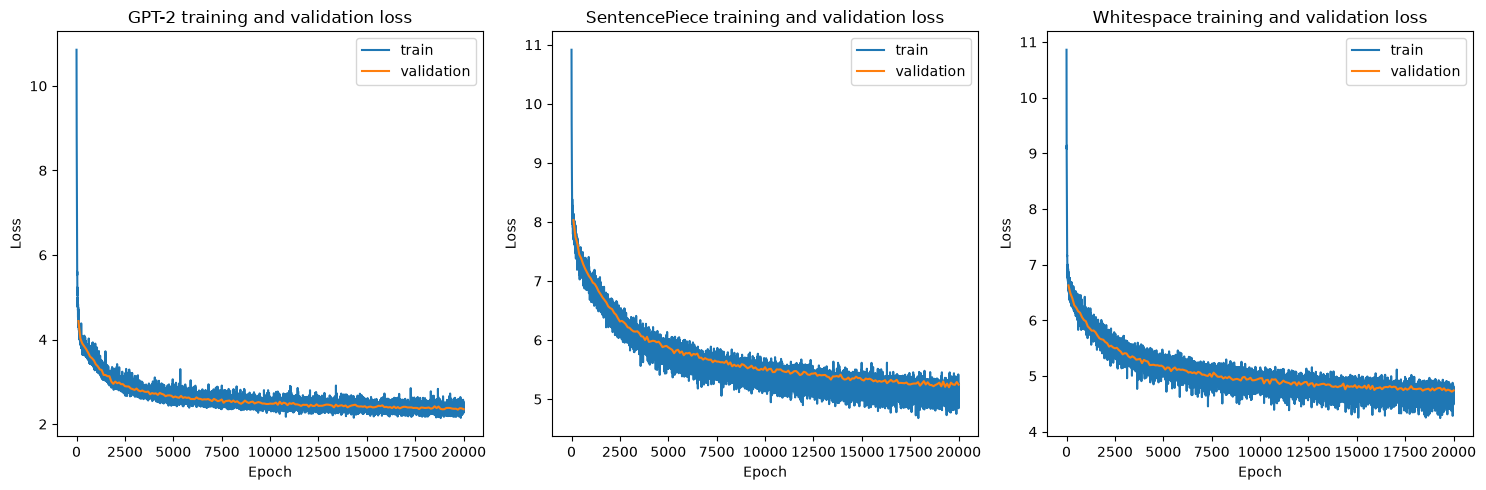

In [22]:
fig, axs = plt.subplots(1, 3, figsize=(15, 5))

axs[0].plot(xs_train, [y['loss'] for y in log_gpt2["train"]], label="train")
axs[0].plot(xs_val, [y['loss'] for y in log_gpt2["validation"]], label="validation")
axs[0].set_title("GPT-2 training and validation loss")
axs[0].set_xlabel("Epoch")
axs[0].set_ylabel("Loss")
axs[0].legend()

axs[1].plot(xs_train, [y['loss'] for y in log_sp["train"]], label="train")
axs[1].plot(xs_val, [y['loss'] for y in log_sp["validation"]], label="validation")
axs[1].set_title("SentencePiece training and validation loss")
axs[1].set_xlabel("Epoch")
axs[1].set_ylabel("Loss")
axs[1].legend()

axs[2].plot(xs_train, [y['loss'] for y in log_ws["train"]], label="train")
axs[2].plot(xs_val, [y['loss'] for y in log_ws["validation"]], label="validation")
axs[2].set_title("Whitespace training and validation loss")
axs[2].set_xlabel("Epoch")
axs[2].set_ylabel("Loss")
axs[2].legend()

plt.tight_layout()
plt.show()

Loading tokenizers

In [23]:
from custom_tokenizers import WhiteSpaceTokenizer, SentencePieceBPETokenizer, GPT2BPETokenizer

In [24]:
whitespace_tokenizer = WhiteSpaceTokenizer()
sentencepiece_tokenizer = SentencePieceBPETokenizer()
gpt2_tokenizer = GPT2BPETokenizer()

whitespace_tokenizer.load("models/ws.model")
sentencepiece_tokenizer.load("models/sp_bpe.model")

Loading transformer models

In [25]:
import torch
from nano_gpt import GPT, GPTConfig

def load_model(path, device):
    checkpoint = torch.load(
        path,
        map_location=device,
        weights_only=True,
    )

    config = GPTConfig(**checkpoint["config"])
    model = GPT(config)
    model.load_state_dict(checkpoint["model"])
    model.to(device)
    model.eval()

    return model

In [26]:
device = "cuda" if torch.cuda.is_available() else "cpu"

In [27]:
model_gpt2_tokenizer = load_model("checkpoints/gpt2.pt", device)
model_sp_tokenizer = load_model("checkpoints/sentencepiece.pt", device)
model_ws_tokenizer = load_model("checkpoints/whitespace.pt", device)

number of parameters: 29.92M
number of parameters: 29.92M
number of parameters: 29.92M


## Test metrics

Words are case-sensitive `\w+` matches. A word is OOV if its individual encoding
contains `unk_id`; punctuation is excluded. Word/character perplexities use the
full test text with the existing line-aligned chunking and independent model blocks.
Single-token word coverage and tokenizer throughput are computed separately below.

In [28]:
from pathlib import Path

CHUNK_SIZE = 1024 * 1024
TEST_PATH = Path("corpus/test.txt")

In [29]:
import numpy as np

def create_test_batches(token_ids, block_size, batch_size):
    target_count = len(token_ids) - 1
    full_blocks = target_count // block_size

    for first_block in range(0, full_blocks, batch_size):
        blocks = min(batch_size, full_blocks - first_block)
        start = first_block * block_size
        end = start + blocks * block_size

        x = token_ids[start:end].astype(np.int64)
        y = token_ids[start + 1:end + 1].astype(np.int64)

        yield (
            x.reshape(blocks, block_size),
            y.reshape(blocks, block_size),
        )

    remainder_start = full_blocks * block_size

    if remainder_start < target_count:
        x = token_ids[remainder_start:-1].astype(np.int64)
        y = token_ids[remainder_start + 1:].astype(np.int64)
        yield x[None, :], y[None, :]

In [30]:
import math
import re
from collections import Counter
import torch
from tqdm.auto import tqdm


@torch.inference_mode()
def evaluate_test(model, tokenizer, test_path=TEST_PATH, batch_size=8, unk_id=None):
    encoded_chunks = []
    word_counts = Counter()
    character_count = 0
    with test_path.open("r", encoding="utf-8") as file:
        while chunk := file.read(CHUNK_SIZE):
            chunk += file.readline()
            encoded_chunks.append(np.asarray(tokenizer.encode(chunk), dtype=np.uint16))
            word_counts.update(re.findall(r"\w+", chunk))
            character_count += len(chunk)

    token_ids = np.concatenate(encoded_chunks)
    word_count = sum(word_counts.values())
    # Check words separately so unknown punctuation does not count as an OOV word
    oov_count = 0
    if unk_id is not None:
        oov_count = sum(
            count for word, count in word_counts.items()
            if unk_id in tokenizer.encode(word)
        )

    model.eval()
    device = next(model.parameters()).device
    total_nll = 0.0
    batches = create_test_batches(token_ids, model.config.block_size, batch_size)
    for x_numpy, y_numpy in tqdm(batches, desc="Test"):
        x = torch.from_numpy(x_numpy).to(device)
        y = torch.from_numpy(y_numpy).to(device)
        _, loss = model(x, y)
        total_nll += loss.item() * y.numel()

    return {
        "word_perplexity": math.exp(total_nll / word_count),
        "character_perplexity": math.exp(total_nll / character_count),
        "word_count": word_count,
        "character_count": character_count,
        "test_tokens": len(token_ids),
        "tokens_per_word": len(token_ids) / word_count,
        "oov_word_count": oov_count,
        "oov_words_percent": 100 * oov_count / word_count,
    }

In [31]:
metrics_gpt2 = evaluate_test(
    model_gpt2_tokenizer, gpt2_tokenizer,
    unk_id=gpt2_tokenizer.tokenizer.unk_token_id,
)
metrics_ws = evaluate_test(
    model_ws_tokenizer, whitespace_tokenizer,
    unk_id=whitespace_tokenizer.unk_token_id,
)
metrics_sp = evaluate_test(
    model_sp_tokenizer, sentencepiece_tokenizer,
    unk_id=sentencepiece_tokenizer.tokenizer.unk_id(),
)

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (588296 > 1024). Running this sequence through the model will result in indexing errors


Test: 0it [00:00, ?it/s]

Test: 0it [00:00, ?it/s]

Test: 0it [00:00, ?it/s]

In [45]:
import pandas as pd
df_metrics = pd.DataFrame({
    "gpt2": metrics_gpt2,
    "whitespace": metrics_ws,
    "sentencepiece": metrics_sp
}).T
df_metrics

,word_perplexity,character_perplexity,word_count,character_count,test_tokens,tokens_per_word,oov_word_count,oov_words_percent
gpt2,6708.074851,3.722725,1621945.0,10872230.0,6016927.0,3.709699,0.0,0.000000
whitespace,359.240077,2.405572,1621945.0,10872230.0,2004373.0,1.235784,227982.0,14.056087
sentencepiece,2319.371421,3.177268,1621945.0,10872230.0,2398549.0,1.478810,3.0,0.000185


<Axes: title={'center': 'Word Perplexity by Model'}>

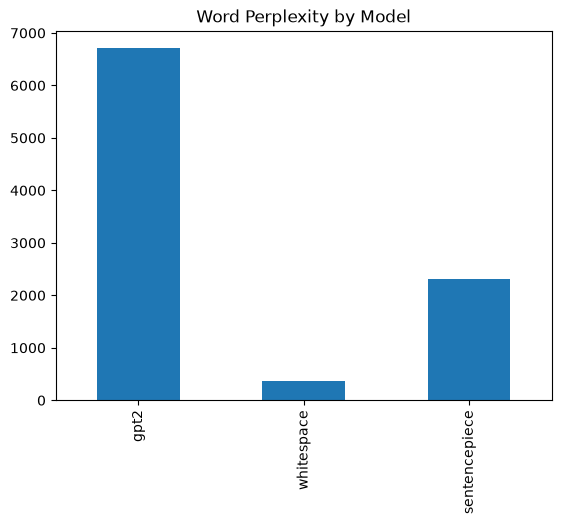

In [33]:
df_metrics["word_perplexity"].plot(kind="bar", title="Word Perplexity by Model")

<Axes: title={'center': 'Character Perplexity by Model'}>

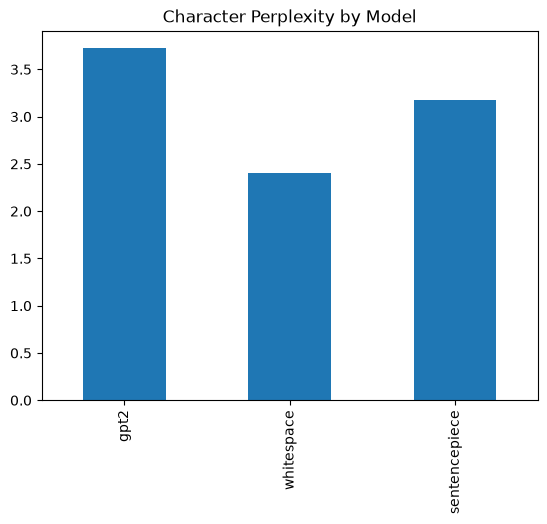

In [42]:
df_metrics["character_perplexity"].plot(kind="bar", title="Character Perplexity by Model")

<Axes: title={'center': 'Test Tokens/Word by Tokenizer'}>

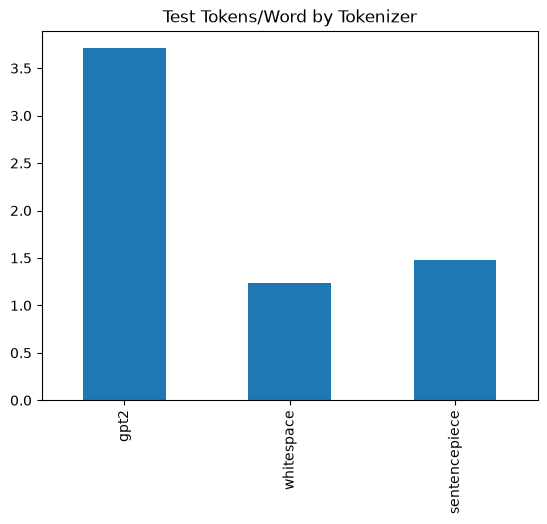

In [34]:
df_metrics["tokens_per_word"].plot(kind="bar", title="Test Tokens/Word by Tokenizer")

<Axes: title={'center': 'Test OOV Words Percent by Tokenizer'}>

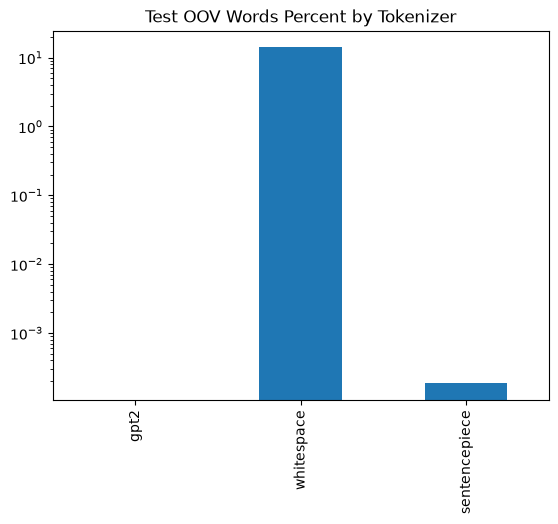

In [40]:
df_metrics["oov_words_percent"].plot(kind="bar", title="Test OOV Words Percent by Tokenizer", logy=True)

### Words directly in vocabulary

In [47]:
from collections import Counter

word_counts = Counter(re.findall(r"\w+", TEST_PATH.read_text(encoding="utf-8")))
word_count = sum(word_counts.values())
word_by_word = {}

for name, tokenizer, unk_id in (
    ("gpt2", gpt2_tokenizer, gpt2_tokenizer.tokenizer.unk_token_id),
    ("whitespace", whitespace_tokenizer, whitespace_tokenizer.unk_token_id),
    ("sentencepiece", sentencepiece_tokenizer, sentencepiece_tokenizer.tokenizer.unk_id()),
):
    direct_count = distinct_direct_count = 0
    for word, occurrences in tqdm(word_counts.items(), desc=name):
        ids = tokenizer.encode(word)
        if len(ids) == 1 and ids[0] != unk_id:
            direct_count += occurrences
            distinct_direct_count += 1

    word_by_word[name] = {
        "word_count": word_count,
        "direct_word_count": direct_count,
        "distinct_direct_words": distinct_direct_count,
        "direct_words_percent": 100 * direct_count / word_count,
    }

df_word_by_word = pd.DataFrame.from_dict(word_by_word, orient="index")
df_word_by_word

gpt2:   0%|          | 0/173118 [00:00<?, ?it/s]

whitespace:   0%|          | 0/173118 [00:00<?, ?it/s]

sentencepiece:   0%|          | 0/173118 [00:00<?, ?it/s]

,word_count,direct_word_count,distinct_direct_words,direct_words_percent
gpt2,1621945,362061,1683,22.322643
whitespace,1621945,1393963,45446,85.943913
sentencepiece,1621945,1325358,29252,81.714115


<Axes: title={'center': 'Percent of words coded directly in vocabulary'}, ylabel='%'>

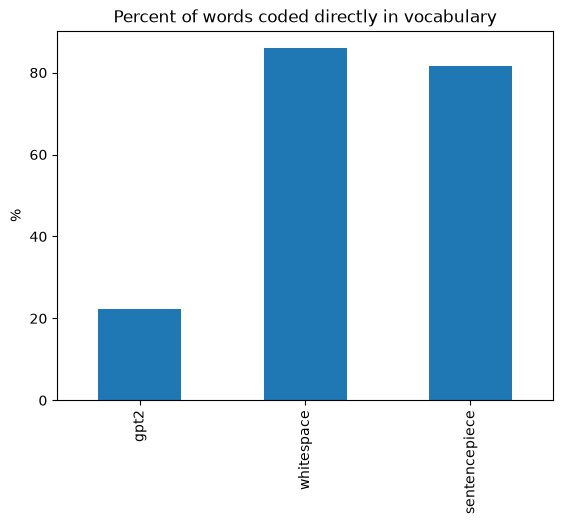

In [49]:
df_word_by_word["direct_words_percent"].plot(kind="bar", title="Percent of words coded directly in vocabulary", ylabel="%")

### Tokenizer throughput

In [36]:
from statistics import median
from time import perf_counter

TOKENIZERS = {
    "gpt2": gpt2_tokenizer,
    "whitespace": whitespace_tokenizer,
    "sentencepiece": sentencepiece_tokenizer,
}

test_chunks = []
with TEST_PATH.open("r", encoding="utf-8") as file:
    while chunk := file.read(CHUNK_SIZE):
        test_chunks.append(chunk + file.readline())
print(f"Test text: {TEST_PATH.stat().st_size / 1024**2:.2f} MiB")

throughput = {}
for name, tokenizer in tqdm(TOKENIZERS.items(), desc="Tokenizer throughput"):
    for text in test_chunks:
        tokenizer.encode(text)

    timings = []
    for _ in range(5):
        start = perf_counter()
        token_count = sum(len(tokenizer.encode(text)) for text in test_chunks)
        timings.append(perf_counter() - start)
    throughput[name] = token_count / median(timings)

df_throughput = pd.Series(throughput, name="tokens_per_second").to_frame()
df_throughput

Test text: 11.18 MiB


Tokenizer throughput:   0%|          | 0/3 [00:00<?, ?it/s]

,tokens_per_second
gpt2,1.305012e+06
whitespace,5.795850e+06
sentencepiece,9.045283e+05


In [50]:
df_throughput.to_markdown()

'|               |   tokens_per_second |\n|:--------------|--------------------:|\n| gpt2          |         1.30501e+06 |\n| whitespace    |         5.79585e+06 |\n| sentencepiece |    904528           |'

### Qualitative examples

In [52]:
from IPython.display import Markdown, display

QUALITATIVE_EXAMPLES = {
    "Common vocabulary": (
        "Pewnego dnia młoda kobieta wyszła z domu i poszła do ogrodu. "
        "Na ławce pod starym drzewem czekał jej brat. Razem patrzyli na niebo, "
        "rozmawiali o rodzinie i zastanawiali się, czy następnego ranka pogoda "
        "pozwoli im wybrać się na długi spacer nad rzekę."
    ),
    "Proper names and rare inflected forms": (
        "Podczas podróży przez Szczebrzeszyn i Hrubieszów Krzysztof Brzęczyszczykiewicz "
        "spotkał Zofię Żółkiewską oraz Grzegorza Przeździeckiego. Rozmawiali o "
        "nieprzewidywalności pogody, dziewięćdziesięciokilometrowej trasie i "
        "najrzadziej odwiedzanych miejscowościach. Wśród pożółkłych dokumentów "
        "odnaleźli nazwiska przodków, zapomniane przydomki oraz szczegółowe opisy "
        "wędrówek odbywanych niegdyś przez tamtejszych mieszkańców."
    ),
    "Specialized vocabulary outside the training domain": (
        "Administrator skonfigurował klaster Kubernetes, uruchomił kontenery i "
        "sprawdził opóźnienia komunikacji między mikroserwisami. Następnie zespół "
        "przeanalizował gradienty transformera, zastosował kwantyzację parametrów "
        "oraz porównał przepustowość tokenizera z wykorzystaniem procesora "
        "graficznego. Wyniki eksperymentu zapisano w repozytorium, a automatyczny "
        "monitoring zgłosił nieoczekiwany wzrost zużycia pamięci podczas inferencji."
    ),
}


for title, text in QUALITATIVE_EXAMPLES.items():
    word_count = len(re.findall(r"\w+", text))
    assert word_count >= 30
    display(Markdown(f"### {title}\nSource: original benchmark text. Words: {word_count}.\n\n> {text}"))
    rows = {}
    for name, tokenizer, unk_id in (
        ("gpt2", gpt2_tokenizer, gpt2_tokenizer.tokenizer.unk_token_id),
        ("whitespace", whitespace_tokenizer, whitespace_tokenizer.unk_token_id),
        ("sentencepiece", sentencepiece_tokenizer, sentencepiece_tokenizer.tokenizer.unk_id()),
    ):
        ids = tokenizer.encode(text)
        direct_count = 0
        for word in re.findall(r"\w+", text):
            word_ids = tokenizer.encode(word)
            if len(word_ids) == 1 and word_ids[0] != unk_id:
                direct_count += 1
        rows[name] = {
            "test_tokens": len(ids),
            "tokens_per_word": len(ids) / word_count,
            "direct_word_count": direct_count,
            "direct_words_percent": 100 * direct_count / word_count,
        }
        if name == "gpt2":
            tokens = tokenizer.tokenizer.convert_ids_to_tokens(ids)
        elif name == "whitespace":
            vocabulary = {token_id: token for token, token_id in tokenizer.vocab.items()}
            tokens = [vocabulary[token_id] for token_id in ids]
        else:
            tokens = [tokenizer.tokenizer.id_to_piece(token_id) for token_id in ids]
        print(f"\n{name}: {tokens}")
    display(pd.DataFrame.from_dict(rows, orient="index"))

### Common vocabulary
Source: original benchmark text. Words: 42.

> Pewnego dnia młoda kobieta wyszła z domu i poszła do ogrodu. Na ławce pod starym drzewem czekał jej brat. Razem patrzyli na niebo, rozmawiali o rodzinie i zastanawiali się, czy następnego ranka pogoda pozwoli im wybrać się na długi spacer nad rzekę.


gpt2: ['P', 'ew', 'ne', 'go', 'Ġd', 'nia', 'Ġm', 'ÅĤ', 'oda', 'Ġk', 'ob', 'iet', 'a', 'Ġw', 'ys', 'z', 'ÅĤ', 'a', 'Ġz', 'Ġdom', 'u', 'Ġi', 'Ġpos', 'z', 'ÅĤ', 'a', 'Ġdo', 'Ġo', 'g', 'rodu', '.', 'ĠNa', 'ĠÅ', 'Ĥ', 'aw', 'ce', 'Ġpod', 'Ġst', 'ary', 'm', 'Ġdr', 'z', 'ew', 'em', 'Ġcz', 'eka', 'ÅĤ', 'Ġje', 'j', 'Ġbr', 'at', '.', 'ĠRaz', 'em', 'Ġpat', 'r', 'z', 'yl', 'i', 'Ġna', 'Ġn', 'ie', 'bo', ',', 'Ġro', 'z', 'm', 'aw', 'ial', 'i', 'Ġo', 'Ġrod', 'zin', 'ie', 'Ġi', 'Ġz', 'ast', 'an', 'aw', 'ial', 'i', 'Ġsi', 'Ä', 'Ļ', ',', 'Ġc', 'zy', 'Ġn', 'ast', 'Ä', 'Ļ', 'p', 'ne', 'go', 'Ġrank', 'a', 'Ġp', 'og', 'oda', 'Ġpo', 'z', 'w', 'oli', 'Ġim', 'Ġw', 'y', 'bra', 'Äĩ', 'Ġsi', 'Ä', 'Ļ', 'Ġna', 'Ġd', 'ÅĤ', 'ugi', 'Ġsp', 'acer', 'Ġn', 'ad', 'Ġr', 'zek', 'Ä', 'Ļ', '.']

whitespace: ['Pewnego', 'dnia', 'młoda', 'kobieta', 'wyszła', 'z', 'domu', 'i', 'poszła', 'do', 'ogrodu', '.', 'Na', 'ławce', 'pod', 'starym', 'drzewem', 'czekał', 'jej', 'brat', '.', 'Razem', 'patrzyli', 'na', 'niebo', ',', 'rozmawial

,test_tokens,tokens_per_word,direct_word_count,direct_words_percent
gpt2,124,2.952381,10,23.809524
whitespace,47,1.119048,41,97.619048
sentencepiece,48,1.142857,41,97.619048


### Proper names and rare inflected forms
Source: original benchmark text. Words: 41.

> Podczas podróży przez Szczebrzeszyn i Hrubieszów Krzysztof Brzęczyszczykiewicz spotkał Zofię Żółkiewską oraz Grzegorza Przeździeckiego. Rozmawiali o nieprzewidywalności pogody, dziewięćdziesięciokilometrowej trasie i najrzadziej odwiedzanych miejscowościach. Wśród pożółkłych dokumentów odnaleźli nazwiska przodków, zapomniane przydomki oraz szczegółowe opisy wędrówek odbywanych niegdyś przez tamtejszych mieszkańców.


gpt2: ['Pod', 'cz', 'as', 'Ġpod', 'r', 'Ã³', 'Å', '¼', 'y', 'Ġpr', 'ze', 'z', 'ĠSz', 'c', 'ze', 'br', 'zes', 'z', 'yn', 'Ġi', 'ĠH', 'rub', 'ies', 'z', 'Ã³', 'w', 'ĠKr', 'z', 'ys', 'z', 'to', 'f', 'ĠBr', 'z', 'Ä', 'Ļ', 'cz', 'ys', 'z', 'c', 'zyk', 'iewicz', 'Ġspot', 'ka', 'ÅĤ', 'ĠZ', 'ofi', 'Ä', 'Ļ', 'ĠÅ', '»', 'Ã³', 'ÅĤ', 'k', 'iew', 'sk', 'Ä', 'ħ', 'Ġor', 'az', 'ĠGr', 'z', 'eg', 'or', 'za', 'ĠPr', 'ze', 'Å', 'º', 'd', 'zie', 'ck', 'ie', 'go', '.', 'ĠRoz', 'm', 'aw', 'ial', 'i', 'Ġo', 'Ġn', 'ie', 'pr', 'z', 'ew', 'idy', 'wal', 'no', 'Å', 'Ľ', 'ci', 'Ġp', 'og', 'ody', ',', 'Ġd', 'z', 'iew', 'i', 'Ä', 'Ļ', 'Äĩ', 'd', 'z', 'ies', 'i', 'Ä', 'Ļ', 'ci', 'ok', 'il', 'omet', 'ro', 'we', 'j', 'Ġtr', 'as', 'ie', 'Ġi', 'Ġn', 'aj', 'r', 'z', 'ad', 'zie', 'j', 'Ġod', 'w', 'ied', 'z', 'any', 'ch', 'Ġm', 'ie', 'j', 'sc', 'ow', 'o', 'Å', 'Ľ', 'ci', 'ach', '.', 'ĠW', 'Å', 'Ľ', 'r', 'Ã³', 'd', 'Ġpo', 'Å', '¼', 'Ã³', 'ÅĤ', 'k', 'ÅĤ', 'y', 'ch', 'Ġdo', 'k', 'ument', 'Ã³', 'w', 'Ġod', 'n', 'ale', 'Å', 'º'

,test_tokens,tokens_per_word,direct_word_count,direct_words_percent
gpt2,237,5.780488,3,7.317073
whitespace,46,1.121951,26,63.414634
sentencepiece,75,1.829268,24,58.536585


### Specialized vocabulary outside the training domain
Source: original benchmark text. Words: 43.

> Administrator skonfigurował klaster Kubernetes, uruchomił kontenery i sprawdził opóźnienia komunikacji między mikroserwisami. Następnie zespół przeanalizował gradienty transformera, zastosował kwantyzację parametrów oraz porównał przepustowość tokenizera z wykorzystaniem procesora graficznego. Wyniki eksperymentu zapisano w repozytorium, a automatyczny monitoring zgłosił nieoczekiwany wzrost zużycia pamięci podczas inferencji.


gpt2: ['Administ', 'rator', 'Ġsk', 'on', 'fig', 'u', 'row', 'a', 'ÅĤ', 'Ġk', 'l', 'aster', 'ĠKu', 'ber', 'net', 'es', ',', 'Ġur', 'uch', 'omi', 'ÅĤ', 'Ġk', 'ont', 'enery', 'Ġi', 'Ġsp', 'raw', 'd', 'zi', 'ÅĤ', 'Ġop', 'Ã³', 'Å', 'º', 'n', 'ien', 'ia', 'Ġk', 'om', 'un', 'ik', 'ac', 'ji', 'Ġmi', 'Ä', 'Ļ', 'd', 'zy', 'Ġm', 'ik', 'ro', 'ser', 'w', 'is', 'ami', '.', 'ĠN', 'ast', 'Ä', 'Ļ', 'p', 'nie', 'Ġz', 'esp', 'Ã³', 'ÅĤ', 'Ġpr', 'ze', 'an', 'al', 'iz', 'owa', 'ÅĤ', 'Ġgradient', 'y', 'Ġtransform', 'era', ',', 'Ġz', 'ast', 'os', 'owa', 'ÅĤ', 'Ġk', 'want', 'yz', 'ac', 'j', 'Ä', 'Ļ', 'Ġparam', 'etr', 'Ã³', 'w', 'Ġor', 'az', 'Ġpor', 'Ã³', 'wn', 'a', 'ÅĤ', 'Ġpr', 'z', 'ep', 'ust', 'ow', 'o', 'Å', 'Ľ', 'Äĩ', 'Ġtoken', 'izer', 'a', 'Ġz', 'Ġw', 'yk', 'or', 'zy', 'st', 'ani', 'em', 'Ġpro', 'ces', 'ora', 'Ġgra', 'f', 'icz', 'ne', 'go', '.', 'ĠWyn', 'iki', 'Ġe', 'ks', 'per', 'y', 'ment', 'u', 'Ġz', 'ap', 'is', 'ano', 'Ġw', 'Ġrepo', 'zy', 'tor', 'ium', ',', 'Ġa', 'Ġautom', 'at', 'y', 'cz', 'ny', 'Ġmon

,test_tokens,tokens_per_word,direct_word_count,direct_words_percent
gpt2,188,4.372093,4,9.302326
whitespace,49,1.139535,16,37.209302
sentencepiece,108,2.511628,12,27.906977
